# House Prices: Model comparison tuning

## 1. Loading and preparing the dataset

In [ ]:
import time

import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, RandomizedSearchCV, cross_validate
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor, plot_tree

pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

In [13]:
TRAIN_PATH = "house-prices-advanced-regression-techniques/train.csv"
TARGET = 'SalePrice'

df = pd.read_csv(TRAIN_PATH)

df['MSSubClass'] = df['MSSubClass'].astype(str)

X = df.drop(columns=[TARGET, 'Id'])
y = df[TARGET].astype(float)

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Exploratory data analysis

In [14]:
num_cols_all = X.select_dtypes(include='number').columns.tolist()
cat_cols_all = X.select_dtypes(exclude='number').columns.tolist()

missing = df.isna().sum()[lambda s: s > 0].sort_values(ascending=False)
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({
    'n_missing': missing,
    'pct_missing': missing_pct,
})
missing_table

,n_missing,pct_missing
PoolQC,1453,99.52
MiscFeature,1406,96.30
Alley,1369,93.77
Fence,1179,80.75
MasVnrType,872,59.73
FireplaceQu,690,47.26
LotFrontage,259,17.74
GarageType,81,5.55
GarageYrBlt,81,5.55
GarageFinish,81,5.55


,SalePrice
count,1460.0
mean,180921.0
std,79443.0
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


Skewness: 1.883
Kurtosis: 6.536
log1p(SalePrice): 0.121


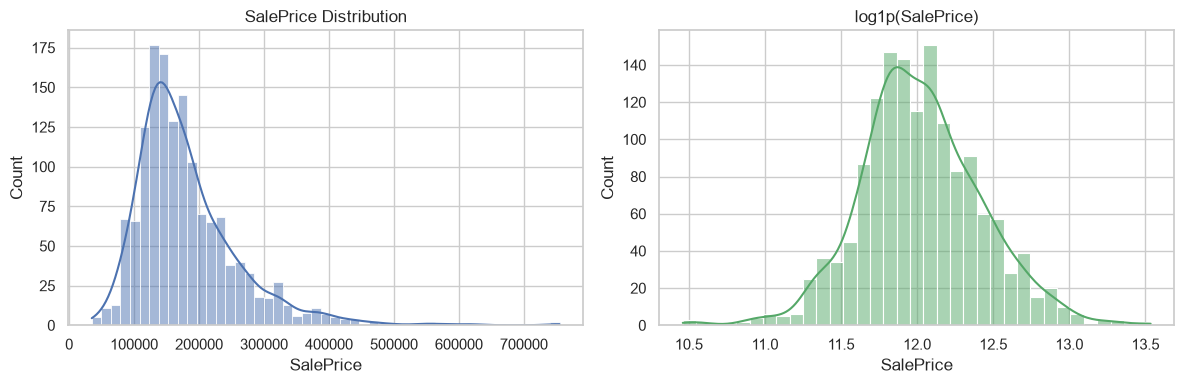

In [15]:
display(df['SalePrice'].describe().to_frame().round(0))
print(f"Skewness: {df['SalePrice'].skew():.3f}")
print(f"Kurtosis: {df['SalePrice'].kurtosis():.3f}")
print(f"log1p(SalePrice): {np.log1p(y).skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], kde=True, ax=axes[0])
axes[0].set_title(f'{TARGET} Distribution')
sns.histplot(np.log1p(y), kde=True, ax=axes[1], color='#55A868')
axes[1].set_title('log1p(SalePrice)')
plt.tight_layout()
plt.show()

In [16]:
rng_df = X[num_cols_all].agg(['min', 'max', 'std']).T
rng_df['range'] = rng_df['max'] - rng_df['min']
display(rng_df.sort_values('range', ascending=False).round(1).head(8))
ratio = rng_df['std'].max() / max(rng_df['std'].min(), 1e-9)
print(f"Ratio of the largest std to the smallest among numeric features: {ratio:,.0f}x")

,min,max,std,range
LotArea,1300.0,215245.0,9981.3,213945.0
MiscVal,0.0,15500.0,496.1,15500.0
TotalBsmtSF,0.0,6110.0,438.7,6110.0
BsmtFinSF1,0.0,5644.0,456.1,5644.0
GrLivArea,334.0,5642.0,525.5,5308.0
1stFlrSF,334.0,4692.0,386.6,4358.0
BsmtUnfSF,0.0,2336.0,441.9,2336.0
2ndFlrSF,0.0,2065.0,436.5,2065.0


Ratio of the largest std to the smallest among numeric features: 45,300x


## 3. Splitting into train, validation, and test sets

In [18]:
bins = pd.qcut(y, q=5, duplicates='drop')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=bins)

print(f"X_train: {X_train.shape} ({len(X_train)/len(X):.0%})")
print(f"X_test:  {X_test.shape} ({len(X_test)/len(X):.0%})")
print(f"Average price: train = {y_train.mean():,.0f}, test = {y_test.mean():,.0f}")

X_train: (1168, 79) (80%)
X_test:  (292, 79) (20%)
Average price: train = 182,257, test = 175,580


## 4–5. Models and Pipeline

In [22]:
def make_preprocessor(X_ref, scale):
    num_cols = X_ref.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X_ref.select_dtypes(include=[str]).columns.tolist()

    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', StandardScaler()))
    cat_steps = [('imputer', SimpleImputer(strategy='constant', fill_value='None')),
                    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]
    return ColumnTransformer([('num', Pipeline(num_steps), num_cols),
                                ('cat', Pipeline(cat_steps), cat_cols)])


def build_pipeline(regressor, scale):
    return Pipeline([
        ('prep', make_preprocessor(X_train, scale)),
        ('model', TransformedTargetRegressor(regressor=regressor, func=np.log1p, inverse_func=np.expm1)),
    ])


BASE_MODELS = {
    'Ridge':             (lambda: Ridge(), True),
    'k-NN':              (lambda: KNeighborsRegressor(), True),
    'SVR (RBF)':         (lambda: SVR(), True),
    'Decision Tree':     (lambda: DecisionTreeRegressor(random_state=SEED), False),
    'Random Forest':     (lambda: RandomForestRegressor(random_state=SEED), False),
    'Gradient Boosting': (lambda: GradientBoostingRegressor(random_state=SEED), False),
}

pipelines = {name: build_pipeline(make(), scale) for name, (make, scale) in BASE_MODELS.items()}

n_out = pipelines['Ridge'].named_steps['prep'].fit(X_train).transform(X_train.head(3)).shape[1]
print(f"Number of features after preprocessing: {n_out}")
pipelines['Random Forest']

Number of features after preprocessing: 313


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output 

## 6-8. Initial evaluation: cross-validation

In [27]:
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}


def run_cv(pipe, n_jobs=-1):
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=n_jobs)
    return {'MAE': -res['test_MAE'], 'RMSE': -res['test_RMSE'], 'R2': res['test_R2'],
            'fit_time': res['fit_time'], 'score_time': res['score_time']}


baseline_cv = {}
for name, pipe in pipelines.items():
    t0 = time.perf_counter()
    baseline_cv[name] = run_cv(pipe)
    print(f"{name:<18} RMSE = {baseline_cv[name]['RMSE'].mean():>9,.0f} ± {baseline_cv[name]['RMSE'].std():>7,.0f}   "
          f"R2 = {baseline_cv[name]['R2'].mean():.4f}   ({time.perf_counter() - t0:.1f} с)")


Ridge              RMSE =    29,553 ±  12,164   R2 = 0.8269   (1.8 с)
k-NN               RMSE =    40,650 ±   4,916   R2 = 0.7429   (1.4 с)
SVR (RBF)          RMSE =    34,121 ±   7,443   R2 = 0.8174   (1.6 с)
Decision Tree      RMSE =    44,251 ±   6,106   R2 = 0.6933   (1.5 с)
Random Forest      RMSE =    31,611 ±   4,030   R2 = 0.8415   (2.0 с)
Gradient Boosting  RMSE =    30,857 ±   6,310   R2 = 0.8405   (0.8 с)


In [28]:
rows = []
for name, r in baseline_cv.items():
    rows.append({
        'Model': name,
        'MAE (mean)': r['MAE'].mean(), 'MAE (std)': r['MAE'].std(),
        'RMSE (mean)': r['RMSE'].mean(), 'RMSE (std)': r['RMSE'].std(),
        'R2 (mean)': r['R2'].mean(), 'R2 (std)': r['R2'].std(),
        'RMSE: std/mean, %': r['RMSE'].std() / r['RMSE'].mean() * 100,
    })
baseline_df = pd.DataFrame(rows).set_index('Model').sort_values('RMSE (mean)')
display(baseline_df.round({'MAE (mean)': 0, 'MAE (std)': 0, 'RMSE (mean)': 0, 'RMSE (std)': 0,
                           'R2 (mean)': 4, 'R2 (std)': 4, 'RMSE: std/mean, %': 1}))

,MAE (mean),MAE (std),RMSE (mean),RMSE (std),R2 (mean),R2 (std),"RMSE: std/mean, %"
Model,,,,,,,
Ridge,15910.0,1206.0,29553.0,12164.0,0.8269,0.1896,41.2
Gradient Boosting,17017.0,449.0,30857.0,6310.0,0.8405,0.0949,20.5
Random Forest,18660.0,1244.0,31611.0,4030.0,0.8415,0.0625,12.7
SVR (RBF),17834.0,1158.0,34121.0,7443.0,0.8174,0.0860,21.8
k-NN,23217.0,1274.0,40650.0,4916.0,0.7429,0.0796,12.1
Decision Tree,27296.0,1853.0,44251.0,6106.0,0.6933,0.1164,13.8


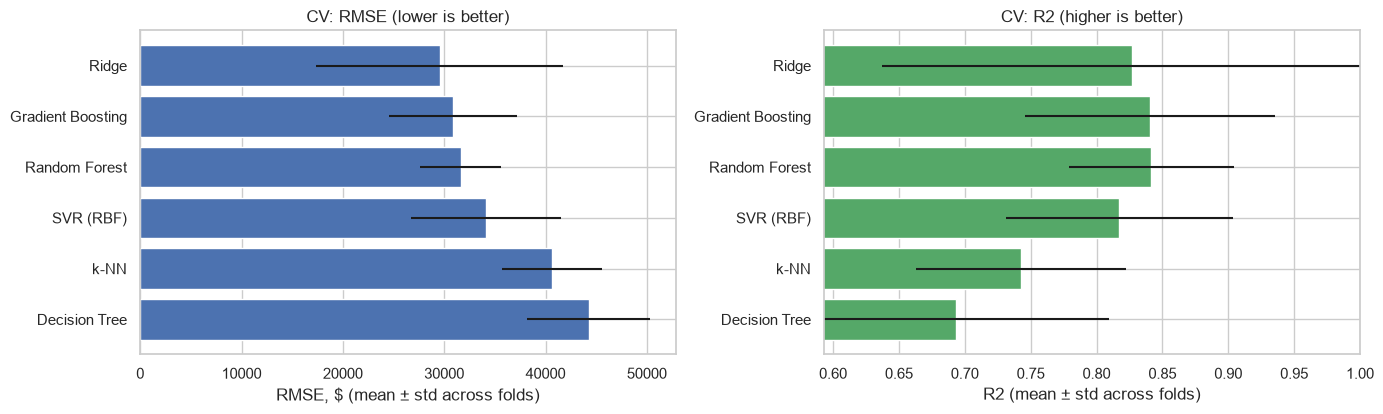

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
order = baseline_df.index
axes[0].barh(order[::-1], baseline_df['RMSE (mean)'][::-1], xerr=baseline_df['RMSE (std)'][::-1])
axes[0].set_xlabel('RMSE, $ (mean ± std across folds)')
axes[0].set_title('CV: RMSE (lower is better)')
axes[1].barh(order[::-1], baseline_df['R2 (mean)'][::-1], xerr=baseline_df['R2 (std)'][::-1], color='#55A868')
axes[1].set_xlabel('R2 (mean ± std across folds)')
axes[1].set_title('CV: R2 (higher is better)')
axes[1].set_xlim(max(0, baseline_df['R2 (mean)'].min() - 0.1), 1.0)
plt.tight_layout()
plt.show()

In [35]:
best_base = baseline_df.index[0]
most_stable = baseline_df['RMSE: std/mean, %'].idxmin()

print(f"Most accurate on CV: {best_base} (RMSE = {baseline_df.loc[best_base, 'RMSE (mean)']:,.0f} $)")
print(f"Most stable (smallest relative RMSE spread across folds): {most_stable} ({baseline_df.loc[most_stable, 'RMSE: std/mean, %']:.1f}%)")

Most accurate on CV: Ridge (RMSE = 29,553 $)
Most stable (smallest relative RMSE spread across folds): k-NN (12.1%)
